In [99]:
%pip install numpy pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Eman\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Setup completed successfully!")




Setup completed successfully!


In [101]:
ratings = pd.read_csv("data/ratings.csv")
movies = pd.read_csv("data/movies.csv")

print(ratings.head())
print(movies.head())

   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  


In [102]:
num_users = ratings["userId"].nunique()
num_movies = ratings["movieId"].nunique()   # 9724
num_ratings = len(ratings)

total_pairs = num_users * num_movies
sparsity = 1 - (num_ratings / total_pairs)

print("Number of users:", num_users)
print("Number of movies:", num_movies)
print("Number of ratings:", num_ratings)
print("Sparsity:", sparsity)
print("Sparsity percentage:", sparsity * 100, "%")

Number of users: 610
Number of movies: 9724
Number of ratings: 100836
Sparsity: 0.9830003169443864
Sparsity percentage: 98.30003169443864 %


In [103]:
rating_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print(rating_matrix.shape)
print(rating_matrix.head())

(610, 9724)
movieId  1       2       3       4       5       6       7       8       \
userId                                                                    
1           4.0     NaN     4.0     NaN     NaN     4.0     NaN     NaN   
2           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
3           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
4           NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
5           4.0     NaN     NaN     NaN     NaN     NaN     NaN     NaN   

movieId  9       10      ...  193565  193567  193571  193573  193579  193581  \
userId                   ...                                                   
1           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
2           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
3           NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN   
4           NaN     NaN  ...     NaN     NaN     NaN     NaN  

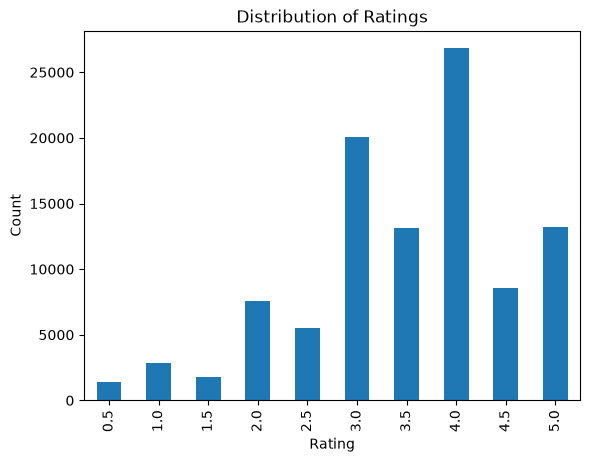

In [104]:
ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution of Ratings"
)

plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

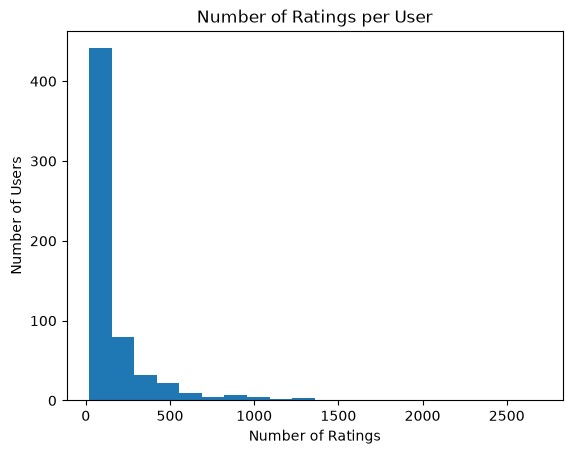

In [105]:
user_rating_counts = ratings.groupby("userId").size()

user_rating_counts.plot(
    kind="hist",
    bins=20,
    title="Number of Ratings per User"
)

plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

In [106]:
print("Mean rating:", ratings["rating"].mean())
print(user_rating_counts.describe())
print("Sparsity %:", sparsity * 100)

Mean rating: 3.501556983616962
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
Sparsity %: 98.30003169443864


<!-- AI-assisted: start -->
1. Distribution of ratings
- The most common rating is 4.0 (about 27,000 ratings), followed by 3.0 (about 20,000), then 3.5 and 5.0 (about 13,000 each).
- Positive ratings (3.5 to 5.0) are far more common than negative ones (0.5 to 2.5). The rarest ratings are 0.5, 1.0 and 1.5.
- The mean rating is 3.501556983616962 which is above the midpoint of the scale (2.75). Users tend to rate positively, probably because they choose to watch movies they expect to like.
- Whole-star ratings (3.0, 4.0, 5.0) are more common than the neighboring half-star ratings (2.5, 3.5, 4.5), so users prefer round numbers.
- each user has a different baseline (generous or harsh), so comparing raw ratings can be misleading. That is why Pearson, which subtracts each user's mean, is expected to work better than Euclidean distance.

2. Number of ratings per user
- The distribution is heavily right-skewed. Most users (about 440 of 610) rated fewer than about 130 movies.
- There is a long tail: a small number of users rated thousands of movies (the most active user rated 2698).
- The median is 70.5 and the mean is 165.304918. The gap between them confirms the skew.

3. Implications for the next parts
- The matrix is extremely sparse (sparsity = 98.30317267467883 %), and most users rated few movies, so two random users will usually share very few co-rated items.
- Because of this, similarity must be computed only over co-rated items, and pairs with fewer than 2 co-rated items must be skipped.
- We should also expect some predictions to return `None` during evaluation.
- Very active users have many more potential neighbors than casual users, so prediction quality will likely vary from user to user.
<!-- AI-assisted: end -->

In [107]:
import numpy as np
import pandas as pd


def get_co_rated(matrix, a, b, axis="index"):
    if axis == "index":
        vec1 = matrix.loc[a]
        vec2 = matrix.loc[b]

    elif axis == "columns":
        vec1 = matrix[a]
        vec2 = matrix[b]

    else:
        raise ValueError("axis must be 'index' or 'columns'")

    mask = vec1.notna() & vec2.notna()

    return (
        vec1[mask].to_numpy(dtype=float),
        vec2[mask].to_numpy(dtype=float)
    )

In [108]:
def euclidean_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None

    distance = np.sqrt(np.sum((vec1 - vec2) ** 2))

    return 1 / (1 + distance)

In [109]:
def cosine_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None

    n1 = np.sqrt(np.sum(vec1 ** 2))
    n2 = np.sqrt(np.sum(vec2 ** 2))

    if n1 == 0 or n2 == 0:
        return None
    dot_product = np.sum(vec1 * vec2)

    return dot_product / (n1 * n2)

In [110]:
def pearson_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) < 2:
        return None
    mean1 = np.mean(vec1)
    mean2 = np.mean(vec2)

    c1 = vec1-mean1
    c2 = vec2-mean2

    n1 = np.sqrt(np.sum(c1 ** 2))
    n2 = np.sqrt(np.sum(c2 ** 2))

    if n1 == 0 or n2 == 0:
        return None

    numerator = np.sum(c1 * c2)
    denominator = n1 * n2

    return numerator / denominator

In [111]:
vec1 = np.array([5, 4, 5, 3], dtype=float)
vec2 = np.array([3, 2, 3, 1], dtype=float)

distance = np.sqrt(np.sum((vec1 - vec2) ** 2))

print("Euclidean distance:", distance)
print("Euclidean similarity:", euclidean_similarity(vec1, vec2))
print("Cosine similarity:", cosine_similarity(vec1, vec2))
print("Pearson similarity:", pearson_similarity(vec1, vec2))

Euclidean distance: 4.0
Euclidean similarity: 0.2
Cosine similarity: 0.9871639953033075
Pearson similarity: 1.0


In [112]:
test_matrix = pd.DataFrame(
    {
        101: [5, 3, np.nan],
        102: [4, np.nan, 2],
        103: [np.nan, 2, 4],
        104: [3, 1, 5]
    },
    index=[1, 2, 3]
)

print(test_matrix)

   101  102  103  104
1  5.0  4.0  NaN    3
2  3.0  NaN  2.0    1
3  NaN  2.0  4.0    5


In [113]:
user1, user2 = get_co_rated(
    test_matrix, 1, 2, axis="index"
)

print("User 1:", user1)
print("User 2:", user2)

User 1: [5. 3.]
User 2: [3. 1.]


In [114]:
movie1, movie2 = get_co_rated(
    test_matrix, 101, 104, axis="columns"
)

print("Movie 101:", movie1)
print("Movie 104:", movie2)

Movie 101: [5. 3.]
Movie 104: [3. 1.]


##  User based Collaborative Filtering

In [115]:
def get_similarity_of_1pair(pair):
    return pair[1]
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    similarities = []

    for other_user in matrix.index:

        if other_user == target_user:
            continue

        vec1, vec2 = get_co_rated(
            matrix, target_user, other_user, axis="index"
        )

        if len(vec1) < 2:
            continue

        score = similarity_fn(vec1, vec2)

        if score is None:
            continue

        similarities.append((other_user, score))

    similarities.sort(key=get_similarity_of_1pair, reverse=True)

    return similarities[:k]

In [116]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_users(
        matrix, target_user, k, similarity_fn
    )

    numerator = 0.0
    denominator = 0.0

    for neighbor_id, similarity in neighbors:

        rating = matrix.loc[neighbor_id, target_item]

        if pd.isna(rating):
            continue

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return None

    return numerator / denominator

## Item based collaborative filtering

In [117]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    similarities = []

    for other_item in matrix.columns:

        if other_item == target_item:
            continue

        vec1, vec2 = get_co_rated(
            matrix, target_item, other_item, axis="columns"
        )

        if len(vec1) < 2:
            continue

        score = similarity_fn(vec1, vec2)

        if score is None:
            continue

        similarities.append((other_item, score))

    similarities.sort(key=get_similarity_of_1pair, reverse=True)

    return similarities[:k]

In [118]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_items(
        matrix, target_item, k, similarity_fn
    )

    numerator = 0.0
    denominator = 0.0

    for neighbor_item, similarity in neighbors:

        rating = matrix.loc[target_user, neighbor_item]

        if pd.isna(rating):
            continue

        numerator += similarity * rating
        denominator += abs(similarity)

    if denominator == 0:
        return None

    return numerator / denominator

changed find_k_nearest_users() into find_k_nearest_items() by iterating over the matrix columns instead of the rows and using axis="columns" to compare movies.

changed predict_rating_user_based() into predict_rating_item_based() to use the target user’s ratings for neighboring movies instead of the neighboring users’ ratings for the target movie.

I also reused the sorting helper get_similarity_of_1pair() from Part C.

In [119]:
def train_test_split_ratings(ratings_df, test_fraction=0.2, seed=42):
    parts = []
    for _, grp in ratings_df.groupby("userId"):
        n_test = max(1, int(round(len(grp) * test_fraction)))
        n_test = min(n_test, len(grp) - 1)          # keep at least 1 training rating
        parts.append(grp.sample(n=n_test, random_state=seed))
    test_df = pd.concat(parts)
    train_df = ratings_df.drop(test_df.index)
    return train_df, test_df

train_df, test_df = train_test_split_ratings(ratings)
train_matrix = train_df.pivot_table(index="userId", columns="movieId", values="rating")
print(len(train_df), len(test_df), train_matrix.shape)

80672 20164 (610, 8970)


In [120]:
def pair_stats(A0, Am, A0sq, t):
    """Co-rated sums between entity t and every other entity.
    A0: values (0 where missing), Am: 1.0 where rated."""
    x0, mx = A0[t], Am[t]
    return dict(n=Am @ mx, sa=Am @ x0, sb=A0 @ mx,
                sa2=Am @ (x0 ** 2), sb2=A0sq @ mx, sab=A0 @ x0)

def sims_from_stats(s, metric, t, min_co=2):
    n, sa, sb, sa2, sb2, sab = (s[x] for x in ("n","sa","sb","sa2","sb2","sab"))
    with np.errstate(divide="ignore", invalid="ignore"):
        if metric == "euclidean":
            d = np.sqrt(np.maximum(sa2 + sb2 - 2 * sab, 0))
            sim = 1 / (1 + d); ok = np.ones(len(n), dtype=bool)
        elif metric == "cosine":
            den = np.sqrt(sa2 * sb2); sim = sab / den; ok = den > 0
        elif metric == "pearson":
            cov = sab - sa * sb / n
            va = sa2 - sa ** 2 / n; vb = sb2 - sb ** 2 / n
            ok = (va > 1e-9) & (vb > 1e-9)
            sim = cov / np.sqrt(va * vb)
    ok = ok & (n >= min_co)
    ok[t] = False                                  # never compare with itself
    return np.where(ok, sim, -np.inf)

def top_neighbors(sim, kmax):
    order = np.argsort(-sim, kind="stable")[:kmax]
    order = order[np.isfinite(sim[order])]
    return order, sim[order]

In [ ]:
METRICS = ["euclidean", "cosine", "pearson"]

def run_grid(train_matrix, test_df, ks=(5, 10, 20, 50), min_co=2):
    users, items = train_matrix.index, train_matrix.columns
    R0 = np.nan_to_num(train_matrix.to_numpy(float))
    M = train_matrix.notna().to_numpy(float)
    u_pos = {u: i for i, u in enumerate(users)}
    c_pos = {m: j for j, m in enumerate(items)}

    n_total = len(test_df)
    td = test_df[test_df.userId.isin(u_pos) & test_df.movieId.isin(c_pos)]
    ui = td.userId.map(u_pos).to_numpy()
    ci = td.movieId.map(c_pos).to_numpy()
    true = td.rating.to_numpy(float)          # items unseen in training -> None

    rows, cache = [], {}
    for method in ["user", "item"]:
        if method == "user":
            A0, Am, targets = R0, M, ui
        else:
            A0, Am, targets = np.ascontiguousarray(R0.T), np.ascontiguousarray(M.T), ci
        A0sq = A0 ** 2
        nb = {m: {} for m in METRICS}
        for t in np.unique(targets):
            s = pair_stats(A0, Am, A0sq, t)
            for m in METRICS:
                nb[m][t] = top_neighbors(sims_from_stats(s, m, t, min_co), max(ks))
        for m in METRICS:
            cache[(method, m)] = nb[m]
            for k in ks:
                preds = np.full(len(true), np.nan)
                for r in range(len(true)):
                    idx, sims = nb[m][targets[r]]
                    idx, sims = idx[:k], sims[:k]
                    if method == "user":
                        rt, mk = R0[idx, ci[r]], M[idx, ci[r]]
                    else:
                        rt, mk = R0[ui[r], idx], M[ui[r], idx]
                    den = (np.abs(sims) * mk).sum()
                    if den > 0:
                        preds[r] = (sims * rt * mk).sum() / den
                ok = ~np.isnan(preds)
                err = preds[ok] - true[ok]
                rows.append(dict(method=method, metric=m, k=k,
                                 RMSE=np.sqrt(np.mean(err ** 2)),
                                 MAE=np.mean(np.abs(err)),
                                 none_fraction=1 - ok.sum() / n_total))
    return pd.DataFrame(rows), cache

results, cache = run_grid(train_matrix, test_df)    
results.round(4)

,method,metric,k,RMSE,MAE,none_fraction
0,user,euclidean,5,1.1824,0.8696,0.9082
1,user,euclidean,10,1.1698,0.8584,0.8467
2,user,euclidean,20,1.1634,0.8593,0.7611
3,user,euclidean,50,1.1182,0.8313,0.5997
4,user,cosine,5,1.2645,0.9292,0.9096
5,user,cosine,10,1.2297,0.9103,0.8484
6,user,cosine,20,1.1954,0.8922,0.7525
7,user,cosine,50,1.1332,0.8480,0.5480
8,user,pearson,5,1.3028,0.9802,0.9038
9,user,pearson,10,1.2702,0.9610,0.8423


In [122]:
for col in ["RMSE", "MAE", "none_fraction"]:
    print(col)
    display(results.pivot_table(index=["method", "metric"], columns="k", values=col).round(4))

RMSE


k                     5       10      20      50
method metric                                   
item   cosine     1.2264  1.1927  1.1653  1.1117
       euclidean  1.1299  1.1090  1.0771  1.0453
       pearson    1.2864  1.2758  1.2645  1.2933
user   cosine     1.2645  1.2297  1.1954  1.1332
       euclidean  1.1824  1.1698  1.1634  1.1182
       pearson    1.3028  1.2702  1.2408  1.1782

MAE


k                     5       10      20      50
method metric                                   
item   cosine     0.9232  0.9010  0.8838  0.8453
       euclidean  0.8489  0.8291  0.8086  0.7852
       pearson    0.9634  0.9485  0.9401  0.9509
user   cosine     0.9292  0.9103  0.8922  0.8480
       euclidean  0.8696  0.8584  0.8593  0.8313
       pearson    0.9802  0.9610  0.9296  0.8878

none_fraction


k                     5       10      20      50
method metric                                   
item   cosine     0.7319  0.6284  0.5212  0.4031
       euclidean  0.7198  0.6199  0.5164  0.3859
       pearson    0.6782  0.5805  0.4892  0.3811
user   cosine     0.9096  0.8484  0.7525  0.5480
       euclidean  0.9082  0.8467  0.7611  0.5997
       pearson    0.9038  0.8423  0.7340  0.4875

In [123]:
R0 = np.nan_to_num(train_matrix.to_numpy(float)); M = train_matrix.notna().to_numpy(float)
users = train_matrix.index
t = 3
s = pair_stats(R0, M, R0**2, t)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    fast = sims_from_stats(s, name, t)
    for o in [10, 50, 200]:
        v1, v2 = get_co_rated(train_matrix, users[t], users[o], axis="index")
        slow = fn(v1, v2)
        if slow is not None:
            assert abs(slow - fast[o]) < 1e-9, (name, o, slow, fast[o])
print("vectorised similarities match the Part B functions")

# slow Part C function on one example, same neighbors as the cache
print(predict_rating_user_based(train_matrix, users[t], train_matrix.columns[0], 20, pearson_similarity))

vectorised similarities match the Part B functions
3.9075723959309823


In [124]:
user_means = train_matrix.mean(axis=1)

def predict_rating_user_based_centered(matrix, target_user, target_item, k, similarity_fn, means):
    num = den = 0.0
    for n_id, sim in find_k_nearest_users(matrix, target_user, k, similarity_fn):
        r = matrix.loc[n_id, target_item]
        if pd.isna(r):
            continue
        num += sim * (r - means[n_id]); den += abs(sim)
    if den == 0:
        return None
    return float(np.clip(means[target_user] + num / den, 0.5, 5.0))

# fast evaluation over the whole test set, reusing the Pearson user-neighbor cache
def eval_centered(train_matrix, test_df, cache, ks=(5, 10, 20, 50)):
    users, items = train_matrix.index, train_matrix.columns
    R0 = np.nan_to_num(train_matrix.to_numpy(float)); M = train_matrix.notna().to_numpy(float)
    mu = train_matrix.mean(axis=1).to_numpy()
    u_pos = {u: i for i, u in enumerate(users)}; c_pos = {m: j for j, m in enumerate(items)}
    td = test_df[test_df.userId.isin(u_pos) & test_df.movieId.isin(c_pos)]
    ui, ci, true = td.userId.map(u_pos).to_numpy(), td.movieId.map(c_pos).to_numpy(), td.rating.to_numpy(float)
    nb, out = cache[("user", "pearson")], []
    for k in ks:
        preds = np.full(len(true), np.nan)
        for r in range(len(true)):
            idx, sims = nb[ui[r]][0][:k], nb[ui[r]][1][:k]
            mk = M[idx, ci[r]]
            den = (np.abs(sims) * mk).sum()
            if den > 0:
                preds[r] = np.clip(mu[ui[r]] + (sims * (R0[idx, ci[r]] - mu[idx]) * mk).sum() / den, 0.5, 5)
        ok = ~np.isnan(preds); err = preds[ok] - true[ok]
        out.append(dict(k=k, RMSE_centered=np.sqrt(np.mean(err**2)), MAE_centered=np.mean(np.abs(err))))
    return pd.DataFrame(out).set_index("k")

cmp = eval_centered(train_matrix, test_df, cache).join(
    results.query("method=='user' and metric=='pearson'").set_index("k")[["RMSE", "MAE"]]
            .rename(columns={"RMSE": "RMSE_plain", "MAE": "MAE_plain"}))
cmp.round(4)

,RMSE_centered,MAE_centered,RMSE_plain,MAE_plain
k,,,,
5,1.2030,0.9274,1.3028,0.9802
10,1.1679,0.9001,1.2702,0.9610
20,1.1372,0.8689,1.2408,0.9296
50,1.0559,0.8054,1.1782,0.8878


In [125]:
def top_n_for_user(user_id, k=50, n=10, metric="pearson", min_co=20, min_support=3):
    R0 = np.nan_to_num(rating_matrix.to_numpy(float)); M = rating_matrix.notna().to_numpy(float)
    t = rating_matrix.index.get_loc(user_id)
    sim = sims_from_stats(pair_stats(R0, M, R0**2, t), metric, t, min_co)
    idx, s = top_neighbors(sim, k)
    num, den, sup = s @ R0[idx], np.abs(s) @ M[idx], M[idx].sum(axis=0)
    cand = (M[t] == 0) & (sup >= min_support) & (den > 0)
    pred = np.where(cand, num / np.where(den > 0, den, 1), -np.inf)
    best = np.argsort(-pred)[:n]
    out = pd.DataFrame({"movieId": rating_matrix.columns[best], "predicted": pred[best], "n_neighbors": sup[best]})
    return out.merge(movies, on="movieId")

user_id = 1
recs = top_n_for_user(user_id); display(recs)

liked = ratings[(ratings.userId == user_id) & (ratings.rating >= 4)].merge(movies, on="movieId")
print("Genres in user's 4+ ratings:\n", liked.genres.str.split("|").explode().value_counts().head(6))
print("Genres in recommendations:\n", recs.genres.str.split("|").explode().value_counts().head(6))

,movieId,predicted,n_neighbors,title,genres
0,1243,5.000000,3.0,Rosencrantz and Guildenstern Are Dead (1990),Comedy|Drama
1,714,5.000000,3.0,Dead Man (1995),Drama|Mystery|Western
2,741,4.822844,3.0,Ghost in the Shell (Kôkaku kidôtai) (1995),Animation|Sci-Fi
3,1276,4.794000,10.0,Cool Hand Luke (1967),Drama
4,1231,4.773425,4.0,"Right Stuff, The (1983)",Drama
5,5225,4.751361,4.0,And Your Mother Too (Y tu mamá también) (2001),Drama|Romance
6,1235,4.735206,4.0,Harold and Maude (1971),Comedy|Drama|Romance
7,1299,4.724401,3.0,"Killing Fields, The (1984)",Drama|War
8,1296,4.722781,3.0,"Room with a View, A (1986)",Drama|Romance
9,922,4.720489,5.0,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance


Genres in user's 4+ ratings:
 genres
Action       76
Adventure    74
Comedy       70
Drama        64
Thriller     43
Fantasy      41
Name: count, dtype: int64
Genres in recommendations:
 genres
Drama        9
Romance      4
Comedy       2
Mystery      1
Western      1
Animation    1
Name: count, dtype: int64
